In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import math
import scipy

In [2]:
semilla = 223
rng = np.random.default_rng(semilla)

df = pd.read_csv("../data/processed/colegios_independencia_PAES2025_desplazados.csv")
df["CLEC_REG_ACTUAL"]=df["CLEC_REG_ACTUAL"] - 100

cantidad_NaN=df["CLEC_REG_ACTUAL"].isna().sum()
cantidad_reales=df["CLEC_REG_ACTUAL"].notna().sum()


In [3]:
datos = df["CLEC_REG_ACTUAL"].dropna().values 

Es la funcion solisitado que devuelve la KDE gaussiana

In [4]:
def ajustar_kde(datos, factor):
    return st.gaussian_kde(datos, bw_method=factor)

Curvas con h distinto para facotres distintos

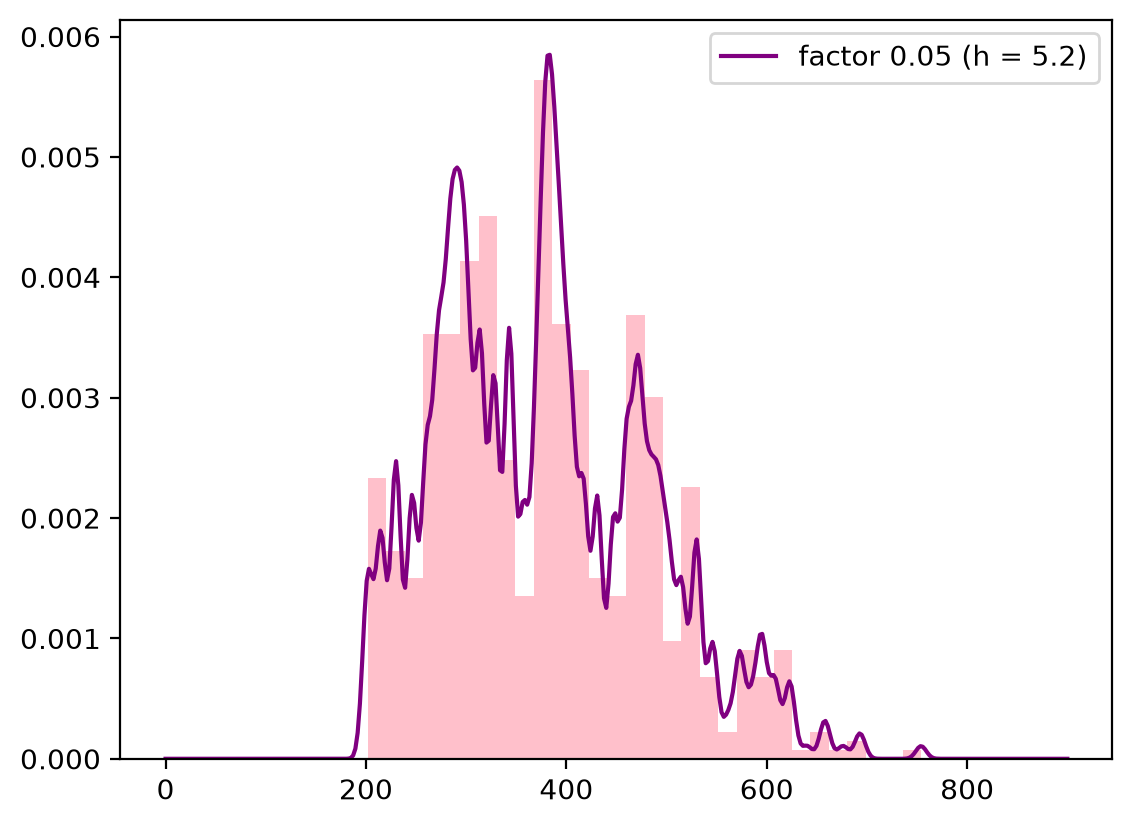

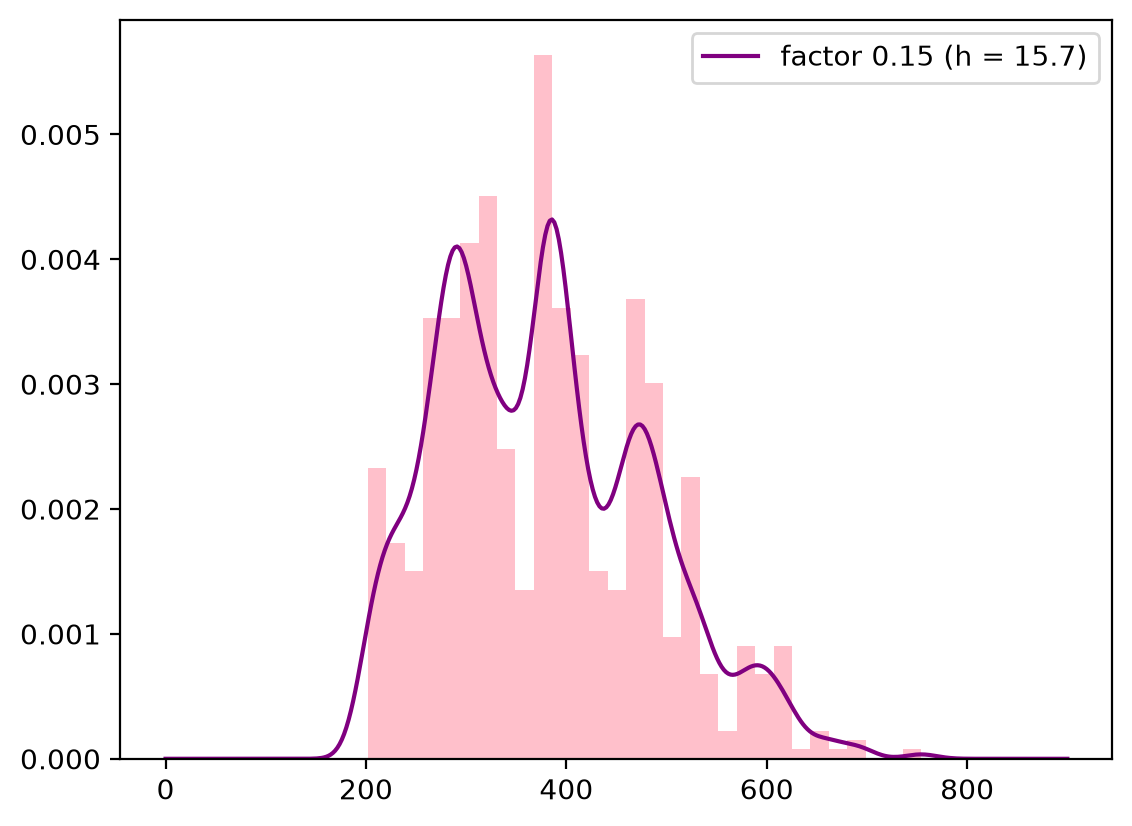

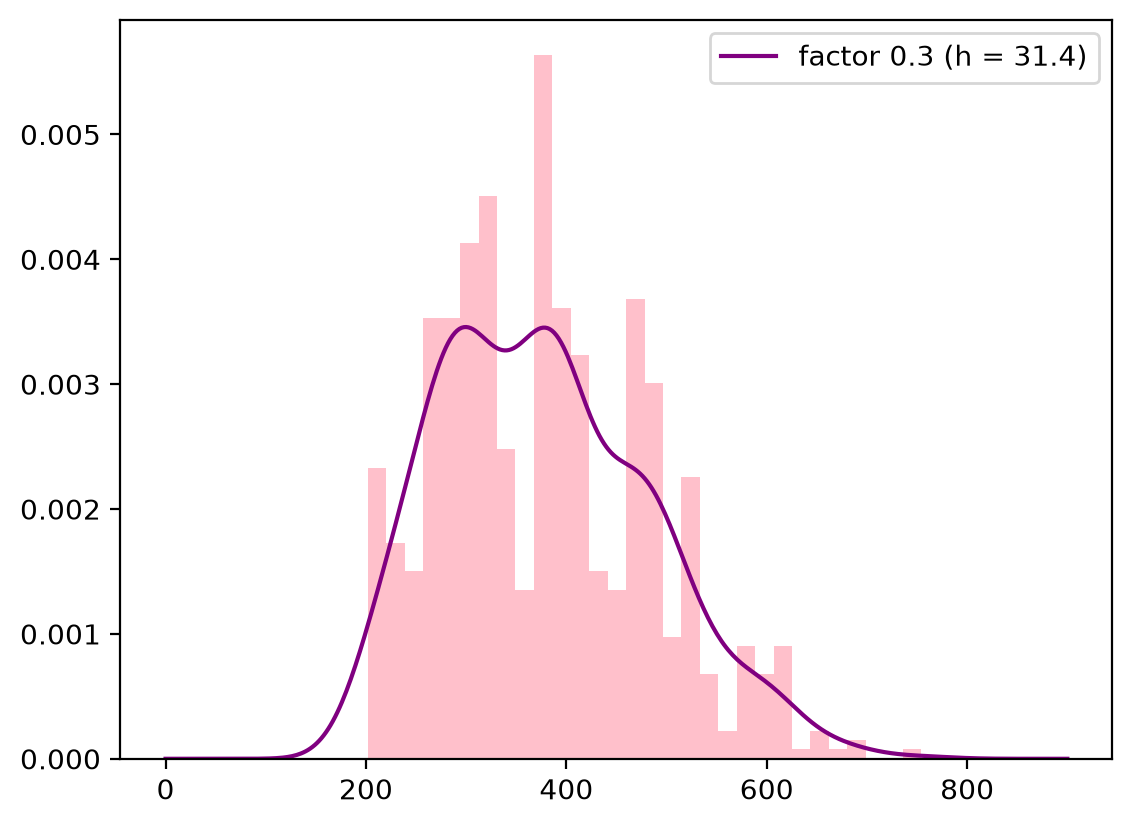

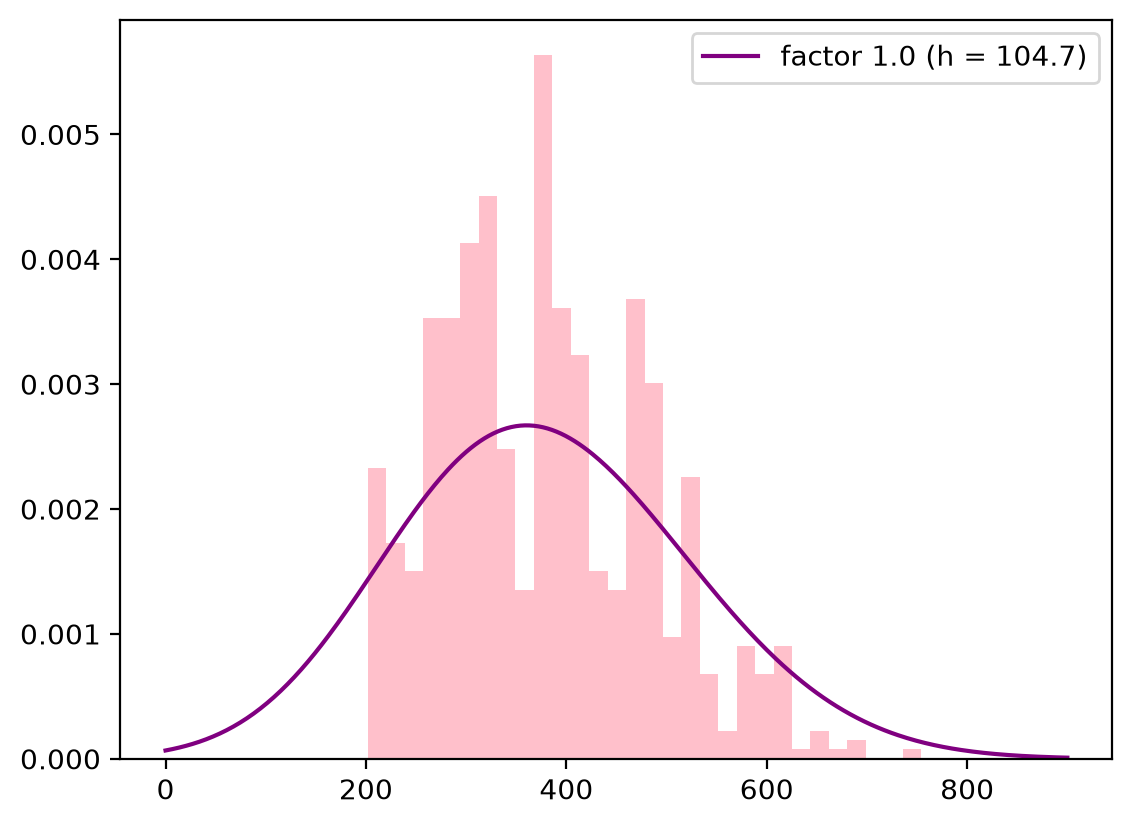

In [ ]:
s = datos.std(ddof=1)
x = np.linspace(0, 900, 400)

#plt.hist(datos, bins=30, density=True, color="pink")
for f in [0.05, 0.15, 0.3, 1.0]:
    kde = ajustar_kde(datos, f)
    plt.hist(datos, bins=30, density=True, color="pink")
    plt.plot(x, kde(x), label=f"factor {f} (h = {f*s:.1f})",color='purple')
    plt.legend()
    #plt.savefig("../results/t2_p3_kde_factores.png")
    plt.show()


iteramos 30 veces para testear cual es el mejor factor. probamos con el 70% escogido al azar. Se escoge el mejor f

In [ ]:
factores = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0]
resultados = {f: [] for f in factores}

for _ in range(30):              
    idx = rng.permutation(len(datos))
    corte = int(0.7 * len(datos))
    train, test = datos[idx[:corte]], datos[idx[corte:]]
    for f in factores:
        gen = ajustar_kde(train, f).resample(len(test), seed=rng)[0]
        resultados[f].append(st.ks_2samp(gen, test).statistic)

medias = {f: np.mean(v) for f, v in resultados.items()}
mejor_f = min(medias, key=medias.get)
print(medias, mejor_f)

In [ ]:
for f, v in resultados.items():
    print(f, np.mean(v), np.std(v))

0.05 0.09431643625192013 0.02822578032747989
0.1 0.08740399385560675 0.025616022584912693
0.15 0.09692780337941628 0.026777943198795163
0.2 0.09170506912442396 0.02353841988778273
0.3 0.09815668202764977 0.02365242258832307
0.5 0.11213517665130567 0.028465522297753613
1.0 0.15007680491551462 0.030070276966060367


ve cuales son los que faltan y luego genera los que faltan y reemplaza la fila rellenada por la que está incompleta

In [ ]:
faltan = df["CLEC_REG_ACTUAL"].isna()

kde_final = ajustar_kde(datos, 0.1)
nuevos = kde_final.resample(faltan.sum(), seed=rng)[0]
nuevos = np.clip(nuevos, 0, 900)           
df.loc[faltan, "CLEC_REG_ACTUAL"] = nuevos

In [ ]:
N=df["CLEC_REG_ACTUAL"].isna().sum()
N

np.int64(0)